# Phân tích dữ liệu Spam/Ham – SV1
Dùng chung các hàm từ `data_analysis.py`. Notebook sẽ tự tìm thư mục gốc dự án từ thư mục làm việc hiện tại (hoặc các thư mục cha).


In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((p for p in candidates if (p / "preprocess.py").is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Không tìm thấy preprocess.py. Hãy mở notebook từ thư mục dự án (hoặc thư mục con).")
sys.path.insert(0, str(PROJECT_DIR))
from preprocess import load_clean_data, STATS_FILE
from data_analysis import summarize, plot_labels, plot_lengths, analyze_data
import pandas as pd
import json
from IPython.display import display, Markdown
df = load_clean_data(PROJECT_DIR / "data" / "emails_clean.csv")
display(df.head())


,subject,body,text,label
0,Laura Bush's 419 letter,URL: http://boingboing.net/#85486499 Date: Not...,Laura Bush's 419 letter URL: http://boingboing...,ham
1,Re: Secure Sofware Key,"> However, cracking and reverse engineering to...","Re: Secure Sofware Key > However, cracking and...",ham
2,Re: no matter where you go,... nor what color your passport? More America...,Re: no matter where you go ... nor what color ...,ham
3,Email marketing info,Untitled Would you like to advertise your webs...,Email marketing info Untitled Would you like t...,spam
4,,THANK YOU FOR SHOPPING WITH US GIFTS FOR ALL O...,THANK YOU FOR SHOPPING WITH US GIFTS FOR ALL O...,spam


## 1. Số lượng email và nhãn


In [2]:
label_stats, length_stats = summarize(df)
display(label_stats)
display(df.isna().sum().rename("NaN"))
display(df[["subject", "body", "text"]].eq("").sum().rename("Số giá trị trống"))


,count,percent
label,,
ham,2408,83.321799
spam,482,16.678201


subject    0
body       0
text       0
label      0
Name: NaN, dtype: int64

subject    3
body       3
text       0
Name: Số giá trị trống, dtype: int64

## 2. Thống kê độ dài email (ký tự)


In [3]:
display(length_stats)
display(df.assign(text_length=df["text"].str.len()).groupby("label")["text_length"].describe(percentiles=[.5,.9,.95,.99]))


,count,mean,median,max,p95
label,,,,,
ham,2408,1402.909884,865.0,88055,3785.15
spam,482,2395.549793,1077.5,126061,7588.35


,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
ham,2408.0,1402.909884,3272.742808,57.0,865.0,2457.3,3785.15,8775.82,88055.0
spam,482.0,2395.549793,7343.159897,11.0,1077.5,3349.9,7588.35,18789.97,126061.0


## 3. Đã bỏ bao nhiêu email trùng/mâu thuẫn?


In [4]:
if STATS_FILE.is_file():
    stats = json.loads(STATS_FILE.read_text(encoding="utf-8"))
    display(pd.DataFrame([stats]))
    display(pd.DataFrame(stats["archives"]))
else:
    print("Chưa có preprocess_stats.json. Chạy python preprocess.py trước.")


,source,archives,valid_before_dedup,contradictory_unique_texts,contradictory_rows_removed,duplicates_removed,total_removed_after_parsing,total_after_cleaning,labels_after_cleaning,empty_subject,empty_body,empty_text,source_term_diagnostics
0,Apache SpamAssassin Public Corpus,"[{'filename': '20021010_easy_ham.tar.bz2', 'la...",3052,0,0,162,162,2890,"{'ham': 2408, 'spam': 482}",3,3,0,"{'spam_term_by_label': {'ham': 233, 'spam': 30..."


,filename,label,members_seen,valid_emails,skipped_empty,skipped_error
0,20021010_easy_ham.tar.bz2,ham,2551,2551,0,0
1,20030228_spam.tar.bz2,spam,501,501,0,0


## 4. Biểu đồ phân bố nhãn và độ dài text (log10)


Tổng email: 2890

Phân bố nhãn:
        count    percent
label                  
ham     2408  83.321799
spam     482  16.678201

Thiếu dữ liệu:
 subject    0
body       0
text       0
label      0

Rỗng subject/body:
 subject    3
body       3

Độ dài văn bản (ký tự):
        count         mean  median     max      p95
label                                             
ham     2408  1402.909884   865.0   88055  3785.15
spam     482  2395.549793  1077.5  126061  7588.35

Loại trùng: 162 ; loại do nhãn mâu thuẫn: 0

Đã lưu: label_distribution.png, length_distribution.png, data_report.md


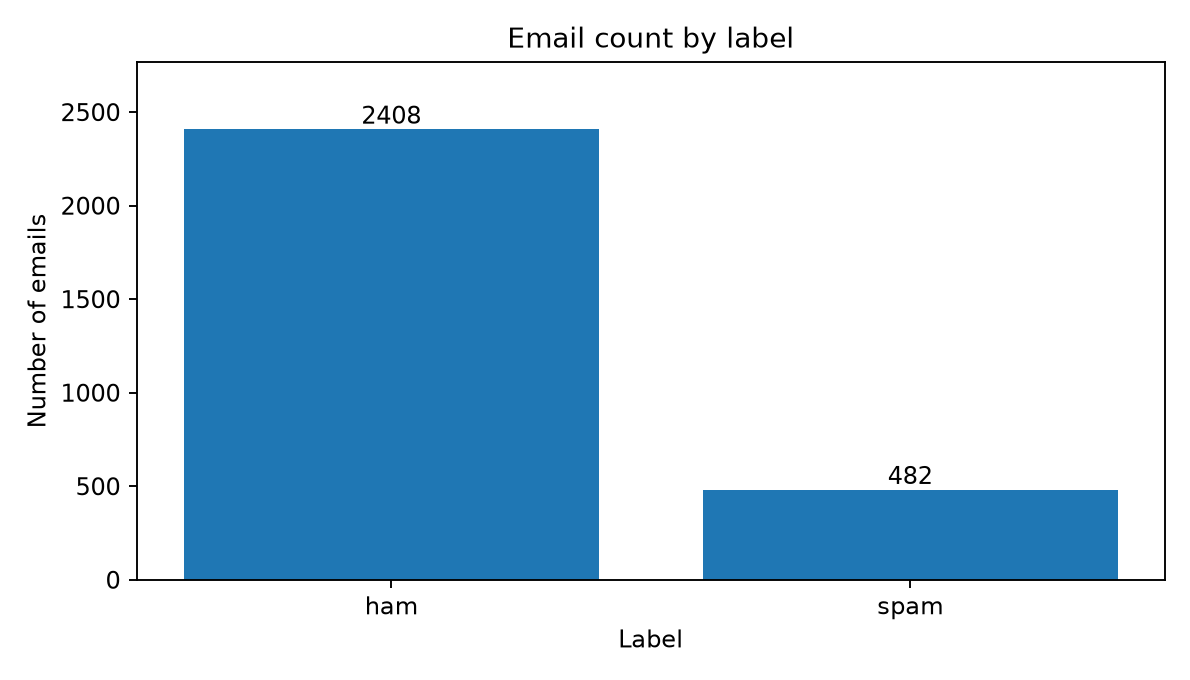

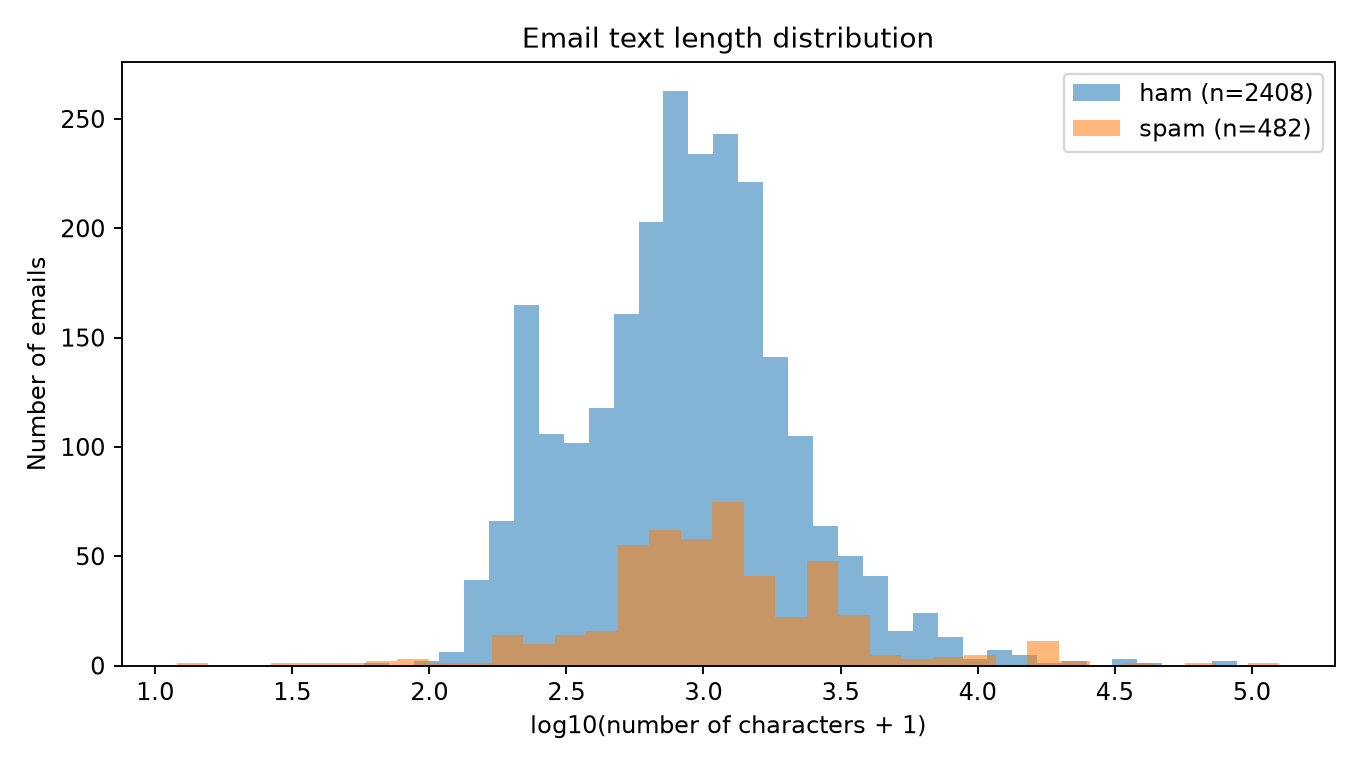

In [5]:
from IPython.display import Image, display
analyze_data(PROJECT_DIR / "data" / "emails_clean.csv", STATS_FILE, PROJECT_DIR / "data")
display(Image(filename=str(PROJECT_DIR / "data" / "label_distribution.png")))
display(Image(filename=str(PROJECT_DIR / "data" / "length_distribution.png")))


## 5. Hạn chế dữ liệu cần ghi vào báo cáo
- Ham nhiều hơn spam: dùng `stratify=df["label"]` khi chia tập và xem macro F1/recall spam.
- Ham có thể mang dấu hiệu mailing list; không chỉ dựa vào accuracy.
- Từ *spam*, *Razor* xuất hiện trong ham; không xóa các từ này một cách máy móc.
- Hai tệp tập hợp ở các thời điểm khác nhau.
- Không dùng corpus thử nghiệm trên hệ thống email sống.
